# **Quick Review: Local Search Algorithms**


**Local Beam Search**

In this example, we will use Local Beam Search to find the minimum of a 2D function that has multiple "*hills and valleys*" (local optima). Local Beam Search tries to avoid getting stuck by exploring multiple promising areas simultaneously.

**Problem:**
Find the minimum of the function `f(x,y)=sin(x)+cos(y)+sin(x⋅y)` within a given range. This function has many local minima.

In [356]:
import random
import math

# Define a 2D objective function with multiple local minima
def objective_function_2d(coords):
    x, y = coords
    # This function has many local minima, global minimum is around -2.0
    return math.sin(x) + math.cos(y) + math.sin(x * y)

# Define the search space bounds for x and y
MIN_COORD, MAX_COORD = -5, 5

# --- Local Beam Search for 2D Function ---
def local_beam_search_2d(objective_func, k, max_iterations, step_factor=0.1):
    """
    Performs Local Beam Search to find the minimum of a 2D objective function.
    """
    # Initialize k random solutions (beams)
    current_solutions = [(random.uniform(MIN_COORD, MAX_COORD), random.uniform(MIN_COORD, MAX_COORD)) for _ in range(k)]
    current_energies = [objective_func(s) for s in current_solutions]

    print(f"\n--- Running Local Beam Search (k={k}) for 2D Function ---")
    print(f"Initial solutions (k beams): {[f'x={s[0]:.2f}, y={s[1]:.2f}, E={e:.2f}' for s, e in zip(current_solutions, current_energies)]}")

    for i in range(max_iterations):
        next_candidates = []
        for sol in current_solutions:
            # Generate neighbors for each current solution
            # We'll generate a few (e.g., 5) random neighbors around each current solution
            for _ in range(5):
                # Create a small random step in both x and y directions
                step_x = random.uniform(-step_factor, step_factor)
                step_y = random.uniform(-step_factor, step_factor)

                neighbor_x = sol[0] + step_x
                neighbor_y = sol[1] + step_y

                # Keep new_solution within bounds
                neighbor_x = max(MIN_COORD, min(neighbor_x, MAX_COORD))
                neighbor_y = max(MIN_COORD, min(neighbor_y, MAX_COORD))

                neighbor_coords = (neighbor_x, neighbor_y)
                next_candidates.append((objective_func(neighbor_coords), neighbor_coords))

        # Select the k best candidates from ALL generated neighbors
        next_candidates.sort(key=lambda x: x[0]) # Sort by energy (lower is better)

        current_solutions = [x[1] for x in next_candidates[:k]]
        current_energies = [x[0] for x in next_candidates[:k]]

        if i % (max_iterations // 5 or 1) == 0: # Print progress periodically
            print(f"Iteration {i}/{max_iterations}, Best k solutions: {[f'E={e:.2f}' for e in current_energies]}")

    best_solution_lbs = min(current_solutions, key=objective_func)
    best_energy_lbs = objective_function_2d(best_solution_lbs)
    print(f"Iteration {i}/{max_iterations}, Best k solutions: {[f'E={e:.2f}' for e in current_energies]}")
    print(f"\nLocal Beam Search Finished. Best found: x={best_solution_lbs[0]:.2f}, y={best_solution_lbs[1]:.2f}, Energy={best_energy_lbs:.2f}")
    return best_solution_lbs, best_energy_lbs

# --- Local Beam Search Example Run ---

print("\n--- Testing Local Beam Search for 2D Function ---")
lbs_solution_2d, lbs_energy_2d = local_beam_search_2d(objective_function_2d,
                                                       k=1, # Number of parallel beams/solutions
                                                       max_iterations=100) # How many iterations


--- Testing Local Beam Search for 2D Function ---

--- Running Local Beam Search (k=1) for 2D Function ---
Initial solutions (k beams): ['x=-4.45, y=4.00, E=1.17']
Iteration 0/100, Best k solutions: ['E=0.92']
Iteration 20/100, Best k solutions: ['E=-0.63']
Iteration 40/100, Best k solutions: ['E=-0.63']
Iteration 60/100, Best k solutions: ['E=-0.64']
Iteration 80/100, Best k solutions: ['E=-0.59']
Iteration 99/100, Best k solutions: ['E=-0.64']

Local Beam Search Finished. Best found: x=-5.00, y=4.04, Energy=-0.64


**Note:** This code uses Local Beam Search to find the minimum value of a 2D mathematical function. You'll see `k` different solutions (beams) being explored simultaneously. In each iteration, the algorithm generates new candidate solutions around all current beams, then picks the k best ones from the entire set of candidates to continue. This helps it explore different parts of the 2D landscape and potentially find better minima than if it just followed one path.



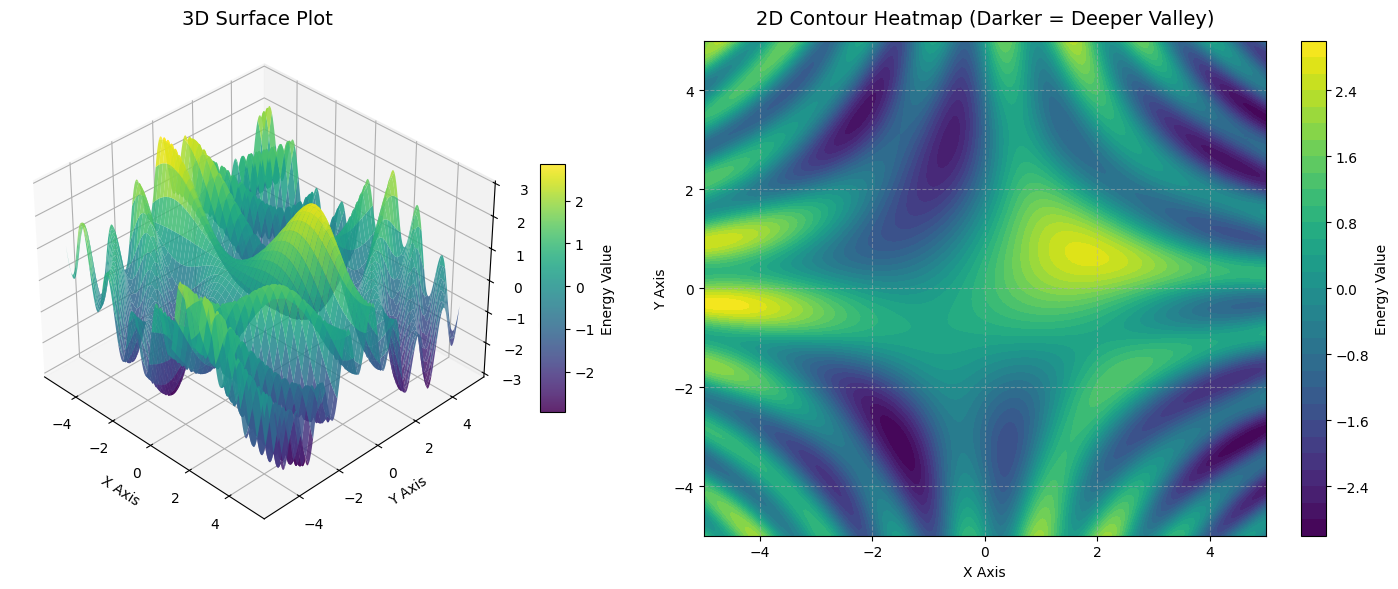

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the search space grid
x = np.linspace(-5, 5, 200)
y = np.linspace(-5, 5, 200)
X, Y = np.meshgrid(x, y)

# 2. Compute the objective function: f(x, y) = sin(x) + cos(y) + sin(x*y)
Z = np.sin(X) + np.cos(Y) + np.sin(X * Y)

# 3. Set up the plotting layout
fig = plt.figure(figsize=(15, 6))

# --- Subplot 1: 3D Surface Plot ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf = ax1.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none', alpha=0.85)

ax1.set_title("3D Surface Plot", fontsize=14, pad=12)
ax1.set_xlabel("X Axis")
ax1.set_ylabel("Y Axis")
ax1.set_zlabel("Energy f(x, y)")
ax1.view_init(elev=35, azim=-45)  # Adjust camera angle for best view

fig.colorbar(surf, ax=ax1, shrink=0.5, aspect=10, label="Energy Value")

# --- Subplot 2: 2D Contour Map (Top-Down View) ---
ax2 = fig.add_subplot(1, 2, 2)
contour = ax2.contourf(X, Y, Z, levels=30, cmap='viridis')

ax2.set_title("2D Contour Heatmap (Darker = Deeper Valley)", fontsize=14, pad=12)
ax2.set_xlabel("X Axis")
ax2.set_ylabel("Y Axis")
ax2.grid(True, linestyle='--', alpha=0.5)

fig.colorbar(contour, ax=ax2, label="Energy Value")

# Show the plot
plt.tight_layout()
plt.show()

**Genetic Algorithms**

Here, we will use a Genetic Algorithm to solve the "***One-Max Problem"***. This is a classic problem where the goal is to evolve a binary string (a sequence of 0s and 1s) to contain as many '1's as possible.

**Problem:** Given a binary string of fixed length, maximize the number of '1's.

In [536]:
import random

# --- Genetic Algorithm for One-Max Problem ---
def genetic_algorithm_one_max(string_length, population_size, mutation_rate, generations):
    """
    Performs a Genetic Algorithm to maximize the number of '1's in a bitstring.
    """

    # 1. Initialize Population: Create a set of random initial solutions (bitstrings)
    population = []
    for _ in range(population_size):
        individual = ''.join(random.choice(['0', '1']) for _ in range(string_length))
        population.append(individual)

    print(f"\n--- Running Genetic Algorithm for One-Max Problem ---")
    print(f"Target: Maximize '1's in a string of length {string_length}")
    print(f"Initial population (first 5 samples): {population[:min(5, population_size)]}...")

    for gen in range(generations):
        # 2. Evaluate Fitness: Determine how 'good' each solution is
        # Fitness: simply the count of '1's in the string
        fitness_scores = []
        for individual in population:
            score = individual.count('1')
            fitness_scores.append(score)

        # Keep track of the best individual in this generation
        best_individual_idx = fitness_scores.index(max(fitness_scores))
        best_individual = population[best_individual_idx]
        best_fitness = fitness_scores[best_individual_idx]

        # Check if we've reached the optimal solution (all '1's)
        if best_fitness == string_length:
            print(f"\nOptimal solution found at Generation {gen}: '{best_individual}' (Fitness: {best_fitness})")
            return best_individual, gen

        # Print progress periodically
        if gen % (generations // 10 or 1) == 0:
            print(f"Generation {gen}: Best individual = '{best_individual}' (Fitness: {best_fitness}/{string_length})")

        # 3. Selection: Choose individuals for reproduction based on their fitness
        # Higher fitness means higher chance of being selected (Roulette Wheel style)
        total_fitness = sum(fitness_scores)
        if total_fitness == 0: # Avoid division by zero if all fitnesses are zero
            selection_probabilities = [1 / population_size] * population_size
        else:
            selection_probabilities = [f / total_fitness for f in fitness_scores]

        # Create the next generation
        new_population = []
        for _ in range(population_size // 2): # Create pairs of offspring until new population is full
            # Select two parents based on fitness probabilities
            parent1 = random.choices(population, weights=selection_probabilities, k=1)[0]
            parent2 = random.choices(population, weights=selection_probabilities, k=1)[0]

            # 4. Crossover (Recombination): Combine genetic material from two parents
            # Here, we use single-point crossover: parents swap parts of their strings
            crossover_point = random.randint(1, string_length - 1)
            child1 = parent1[:crossover_point] + parent2[crossover_point:]
            child2 = parent2[:crossover_point] + parent1[crossover_point:]

            # 5. Mutation: Introduce small, random changes to maintain diversity
            def mutate(individual, rate):
                mutated_individual = list(individual)
                for i in range(string_length):
                    if random.random() < rate: # With a small probability, flip a bit
                        mutated_individual[i] = '1' if mutated_individual[i] == '0' else '0'
                return "".join(mutated_individual)

            new_population.append(mutate(child1, mutation_rate))
            new_population.append(mutate(child2, mutation_rate))

        population = new_population # Replace old population with the new generation

    print(f"\nGenetic Algorithm Finished. Best found: '{best_individual}' (Fitness: {best_fitness}/{string_length})")
    return best_individual, best_fitness

# --- Genetic Algorithm Example Run ---
print("\n--- Testing Genetic Algorithm for One-Max Problem ---")
ga_best_solution_om, ga_generations_om = genetic_algorithm_one_max(string_length=20, # Length of the binary string
                                                                    population_size=10, # Number of individuals
                                                                    mutation_rate=0.01, # Probability of a bit flipping
                                                                    generations=200) # How many generations


--- Testing Genetic Algorithm for One-Max Problem ---

--- Running Genetic Algorithm for One-Max Problem ---
Target: Maximize '1's in a string of length 20
Initial population (first 5 samples): ['01100011001101000010', '11101101000100110101', '10001011010000001010', '10000011011011010000', '01011011011110100010']...
Generation 0: Best individual = '11011101110110000111' (Fitness: 13/20)
Generation 20: Best individual = '11011101110110000111' (Fitness: 13/20)
Generation 40: Best individual = '11111111111101001110' (Fitness: 16/20)
Generation 60: Best individual = '11110111111101001110' (Fitness: 15/20)
Generation 80: Best individual = '00111101111101011110' (Fitness: 14/20)
Generation 100: Best individual = '01111100111101011111' (Fitness: 15/20)
Generation 120: Best individual = '10111000111001011110' (Fitness: 12/20)
Generation 140: Best individual = '00111101111001011111' (Fitness: 14/20)
Generation 160: Best individual = '01101101011001011110' (Fitness: 12/20)
Generation 180: Best 

**Note:** This Genetic Algorithm aims to create a binary string full of '1's. You'll see the "***Fitness***" score (the count of '1's) of the best individual in each generation generally increase. This demonstrates how selection favors individuals closer to the goal, crossover combines their traits, and mutation introduces new variations, allowing the population to "evolve" towards the optimal solution.



**Question:**

Try changing the `k` value (number of beams). What happens if `k` is very small (e.g., `1` or `2`)? What if it iss very large (e.g., `50`)? How does this affect the final energy found and the algorithm's exploration?

In [ ]:
#If the k value is too small, the algorithm may converge to a local minimum and may not find the global minimum.

#If the k value is too high, it may require more computational resources and time to evaluate all beams, 
# but it increases the chances of finding a better solution.

#The more k value u increase the more faster you can find the better solution and the energy will be more lower. 

**Question:**

How does changing the `mutation_rate` affect the algorithm's performance? What happens if it's too high or too low? Why is a balanced `mutation_rate` important for Genetic Algorithms?

In [ ]:
#If the mutation rate is too low, the result in the genetic alogorithm may converge to a local optimum and 
# may not explore the solution space effectively, leading to suboptimal solutions. 

#If the mutation rate is too high, it may disrupt the convergence process and prevent the algorithm 
# from effectively exploiting good solutions, leading to a random search behavior.

#The importance of balanced mutation rate is crucial for the success of the 
# genetic algorithm, as it helps maintain diversity in the population while allowing for convergence towards optimal solutions.


**Exercise 1:**
*   Keep `string_length` at `20`, `mutation_rate` at `0.02`, and `generations` at `200`.
*   Experiment by running the `genetic_algorithm_one_max `function with three different population_size values:

   Small: `population_size = 10`

   Medium: `population_size = 100` (the default)

   Large: `population_size = 500`
*   For each run, note the number of generations it took to find the optimal solution (all '1's), or if it did not find it, note the best fitness achieved.


Based on your results, explain how `population_size` affects the algorithm's convergence speed and its ability to find the optimal solution. What are the trade-offs of using a very small vs. a very large population?

**Exercise 2:**

The current code uses single-point crossover, where the genetic material is split at one random point. Other crossover methods exist, such as two-point crossover or uniform crossover.

*   Locate the section in the `genetic_algorithm_one_max` function where crossover occurs (around `crossover_point = random.randint(1, string_length - 1)`).
*  Modify the crossover operation to implement two-point crossover.
*  Instead of one `crossover_point`, you will need two random points. Ensure `point1 < point2`.
*  The children will be formed by taking the first segment from `parent1`, the middle segment from `parent2`, and the last segment from `parent1` (and vice-versa for `child2`).

   Example:
  
  `Parent1 = AAAA BBBB CCCC`

  `Parent2 = XXXX YYYY ZZZZ`

  `Child1 = AAAA YYYY CCCC`

  `Child2 = XXXX BBBB ZZZZ`

*   Run the modified GA with `string_length=20`, `population_size=100`, `mutation_rate=0.0`2, and `generations=200`.

Compare the performance (generations to converge, or final fitness) of your two-point crossover implementation against the original single-point crossover. In what scenarios might one crossover method be more advantageous than the other for problems like `One-Max`?

In [ ]:
#If the mutation rate is too low, the result will 